# Agricultural Water Decoupling in France

## Research Question

Has agricultural water use become decoupled from
agricultural production in France?

## Hypotheses

**H1:** Agricultural water withdrawal intensity has
decreased over time in at least some French regions.

**H2:** Improvements in water withdrawal intensity
do not necessarily translate into reductions in
total agricultural water withdrawals.

**H3:** The relationship between agricultural
production and water withdrawals varies
substantially across French regions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Environment ready!")
print("Pandas version:", pd.__version__)

Environment ready!
Pandas version: 3.1.1


## 2. Data Exploration

### 2.1 Dataset Inspection

Before processing the datasets, we will inspect their
structure, variables, temporal coverage and missing values.

In [2]:
from pathlib import Path

# Path to the raw data folder
data_path = Path("../data/raw")

# List available files
files = list(data_path.iterdir())

for file in files:
    print(f"File: {file.name}")
    print(f"Extension: {file.suffix}")
    print(f"Size: {file.stat().st_size / 1024:.1f} KB")
    print("-" * 40)

File: .DS_Store
Extension: 
Size: 6.0 KB
----------------------------------------
File: prelevements-d-eau-par-usage-region.csv
Extension: .csv
Size: 273.6 KB
----------------------------------------
File: regions.geojson
Extension: .geojson
Size: 1418.3 KB
----------------------------------------
File: SériesComptesRégionaux_2010-2025_départementales_et_régionales.xlsx
Extension: .xlsx
Size: 15925.2 KB
----------------------------------------


### 2.2 Water Withdrawal Dataset — BNPE

We will inspect the dataset structure, identify its variables,
and evaluate its geographical and temporal coverage.

In [3]:
# Select the BNPE dataset
bnpe_file = data_path / "prelevements-d-eau-par-usage-region.csv"

# Inspect the first lines of the raw file
with open(bnpe_file, "r", encoding="utf-8-sig") as f:
    for i in range(5):
        print(f.readline().strip())

date_mesure,geocode_region,libelle_region,type_eau,usage,valeur
2008-01-01,11,Île-de-France,eaux douces souterraines,agriculture,15995893.1
2008-01-01,11,Île-de-France,eaux douces souterraines,eau potable,281671820.9948373
2008-01-01,11,Île-de-France,eaux douces souterraines,industrie et autres usages économiques,28398563.099999998
2008-01-01,11,Île-de-France,eaux douces souterraines,refroidissement des centrales électriques,272559.0


In [4]:
# Load the BNPE dataset
df_bnpe = pd.read_csv(bnpe_file)

# Display the first rows
display(df_bnpe.head())

# Dataset dimensions
print("Rows and columns:", df_bnpe.shape)

# Column names and data types
df_bnpe.info()

,date_mesure,geocode_region,libelle_region,type_eau,usage,valeur
0,2008-01-01,11,Île-de-France,eaux douces souterraines,agriculture,1.599589e+07
1,2008-01-01,11,Île-de-France,eaux douces souterraines,eau potable,2.816718e+08
2,2008-01-01,11,Île-de-France,eaux douces souterraines,industrie et autres usages économiques,2.839856e+07
3,2008-01-01,11,Île-de-France,eaux douces souterraines,refroidissement des centrales électriques,2.725590e+05
4,2008-01-01,11,Île-de-France,eaux douces superficielles,agriculture,1.125050e+06


Rows and columns: (3204, 6)
<class 'pandas.DataFrame'>
RangeIndex: 3204 entries, 0 to 3203
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date_mesure     3204 non-null   str    
 1   geocode_region  3204 non-null   int64  
 2   libelle_region  3204 non-null   str    
 3   type_eau        3204 non-null   str    
 4   usage           3204 non-null   str    
 5   valeur          3204 non-null   float64
dtypes: float64(1), int64(1), str(4)
memory usage: 150.3 KB


In [5]:
# Extract year from the observation date
df_bnpe["year"] = pd.to_datetime(
    df_bnpe["date_mesure"]
).dt.year

# Temporal coverage
print("First year:", df_bnpe["year"].min())
print("Last year:", df_bnpe["year"].max())
print("Available years:", sorted(df_bnpe["year"].unique()))

# Geographic coverage
print("\nNumber of regions:", df_bnpe["libelle_region"].nunique())
print("Regions:")
print(sorted(df_bnpe["libelle_region"].unique()))

# Water withdrawal categories
print("\nUses:")
print(df_bnpe["usage"].value_counts())

# Water source categories
print("\nWater types:")
print(df_bnpe["type_eau"].value_counts())

First year: 2008
Last year: 2022
Available years: [np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022)]

Number of regions: 18
Regions:
['Auvergne-Rhône-Alpes', 'Bourgogne-Franche-Comté', 'Bretagne', 'Centre-Val de Loire', 'Corse', 'Grand Est', 'Guadeloupe', 'Guyane', 'Hauts-de-France', 'La Réunion', 'Martinique', 'Mayotte', 'Normandie', 'Nouvelle-Aquitaine', 'Occitanie', 'Pays de la Loire', "Provence-Alpes-Côte d'Azur", 'Île-de-France']

Uses:
usage
refroidissement des centrales électriques    750
agriculture                                  698
industrie et autres usages économiques       698
alimentation des canaux                      558
eau potable                                  500
Name: count, dtype: int64

Water types:
type_eau
eaux douces souterraines      1198
eaux douces superficielles   

In [6]:
uv add geopandas mapclassify

/Users/vicentefilho/Documents/DataSciences/Project Vicente 2026/.venv/bin/python: No module named uv
Note: you may need to restart the kernel to use updated packages.


### 2.4 Spatial Distribution of Agricultural Water Withdrawals

This section compares regional agricultural water withdrawals
in France in 2008 and 2022 using choropleth maps.

In [7]:
# Keep only agricultural withdrawals
df_agri = df_bnpe[df_bnpe["usage"] == "agriculture"].copy()

# Aggregate groundwater and surface water withdrawals
water_region = (
    df_agri[df_agri["year"].isin([2008, 2022])]
    .groupby(
        ["year", "geocode_region", "libelle_region"],
        as_index=False
    )["valeur"]
    .sum()
)

display(water_region.head(10))

,year,geocode_region,libelle_region,valeur
0,2008,11,Île-de-France,1.712094e+07
1,2008,24,Centre-Val de Loire,2.181604e+08
2,2008,27,Bourgogne-Franche-Comté,1.013260e+07
3,2008,28,Normandie,4.476049e+06
4,2008,32,Hauts-de-France,3.105813e+07
5,2008,44,Grand Est,1.065579e+08
6,2008,52,Pays de la Loire,1.423034e+08
7,2008,53,Bretagne,7.072900e+06
8,2008,75,Nouvelle-Aquitaine,5.448282e+08
9,2008,76,Occitanie,6.173572e+08


In [8]:
import geopandas as gpd

regions = gpd.read_file("../data/raw/regions.geojson")

print("Number of regions:", len(regions))
print("Columns:", regions.columns.tolist())

display(regions.head())

Number of regions: 13
Columns: ['code', 'nom', 'geometry']


,code,nom,geometry
0,11,Île-de-France,"POLYGON ((2.59052 49.07965, 2.59602 49.08171, ..."
1,24,Centre-Val de Loire,"POLYGON ((2.87463 47.52042, 2.87984 47.51671, ..."
2,27,Bourgogne-Franche-Comté,"POLYGON ((3.62942 46.74946, 3.62655 46.75228, ..."
3,28,Normandie,"MULTIPOLYGON (((-1.11962 49.35557, -1.11554 49..."
4,32,Hauts-de-France,"POLYGON ((4.1409 49.97876, 4.14407 49.97625, 4..."


In [9]:
display(regions[["code", "nom"]])

,code,nom
0,11,Île-de-France
1,24,Centre-Val de Loire
2,27,Bourgogne-Franche-Comté
3,28,Normandie
4,32,Hauts-de-France
5,44,Grand Est
6,52,Pays de la Loire
7,53,Bretagne
8,75,Nouvelle-Aquitaine
9,76,Occitanie


In [10]:
# Standardize regional codes in both datasets
regions["region_code"] = regions["code"].astype(str).str.zfill(2)

water_region["region_code"] = (
    water_region["geocode_region"].astype(str).str.zfill(2)
)

# Merge geographical boundaries with water withdrawal data
map_data = regions.merge(
    water_region,
    on="region_code",
    how="left"
)

# Check if all regions have data for both years
print(
    map_data.groupby("year")["valeur"]
    .agg(["count", "min", "max"])
)

display(map_data[["nom", "year", "valeur"]].head(10))

      count        min          max
year                               
2008     13  4476049.0  671011200.0
2022     13  9122145.0  768617734.0


,nom,year,valeur
0,Île-de-France,2008,1.712094e+07
1,Île-de-France,2022,3.553865e+07
2,Centre-Val de Loire,2008,2.181604e+08
3,Centre-Val de Loire,2022,3.703254e+08
4,Bourgogne-Franche-Comté,2008,1.013260e+07
5,Bourgogne-Franche-Comté,2022,2.207787e+07
6,Normandie,2008,4.476049e+06
7,Normandie,2022,1.390054e+07
8,Hauts-de-France,2008,3.105813e+07
9,Hauts-de-France,2022,1.166978e+08


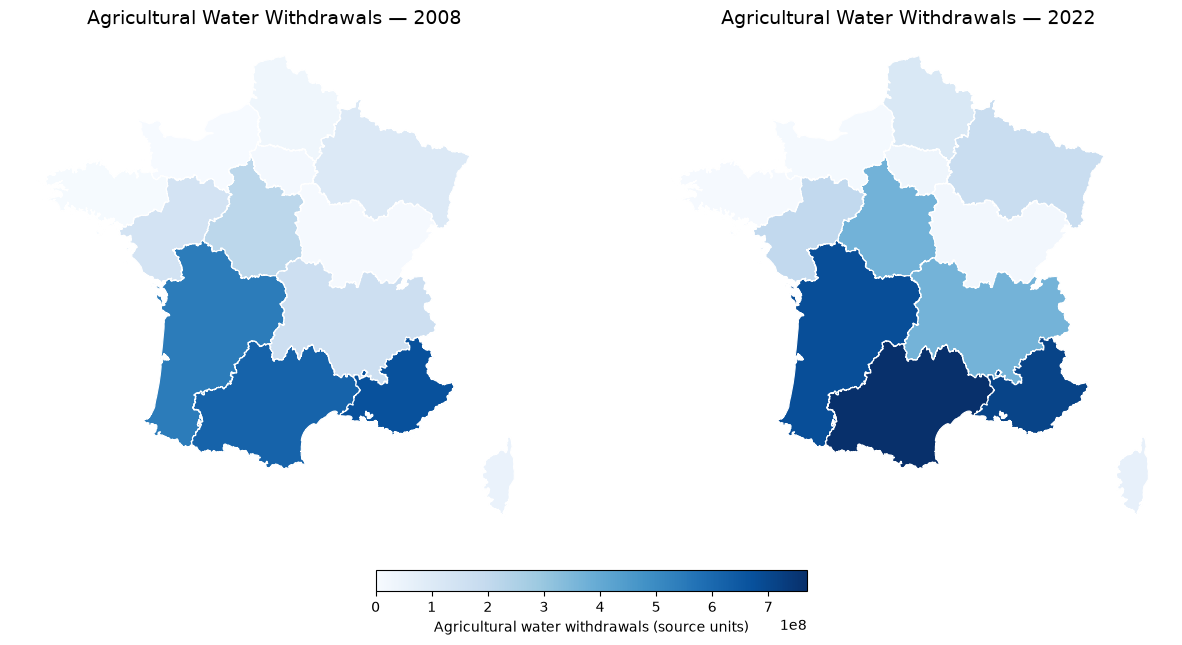

In [11]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# Same color scale for both years
vmin = 0
vmax = map_data["valeur"].max()

fig, axes = plt.subplots(1, 2, figsize=(15, 8))

for ax, year in zip(axes, [2008, 2022]):

    year_data = map_data[map_data["year"] == year]

    year_data.plot(
        column="valeur",
        ax=ax,
        cmap="Blues",
        vmin=vmin,
        vmax=vmax,
        edgecolor="white",
        linewidth=0.8,
        legend=False,
        missing_kwds={"color": "lightgrey"}
    )

    ax.set_title(
        f"Agricultural Water Withdrawals — {year}",
        fontsize=14
    )
    ax.set_axis_off()

# Shared colorbar
sm = ScalarMappable(
    norm=Normalize(vmin=vmin, vmax=vmax),
    cmap="Blues"
)

sm.set_array([])

fig.colorbar(
    sm,
    ax=axes,
    orientation="horizontal",
    fraction=0.035,
    pad=0.05,
    label="Agricultural water withdrawals (source units)"
)

plt.show()

### 2.5 Changes in Agricultural Water Withdrawals (2008–2022)

This section quantifies changes in agricultural water withdrawals
across French regions between 2008 and 2022.

In [12]:
# Compare regional withdrawals between 2008 and 2022
comparison = water_region.pivot(
    index="libelle_region",
    columns="year",
    values="valeur"
)

# Calculate percentage change
comparison["change_pct"] = (
    (comparison[2022] - comparison[2008])
    / comparison[2008]
) * 100

# Sort regions by percentage change
comparison = comparison.sort_values(
    "change_pct",
    ascending=False
)

display(comparison.round(2))

year,2008,2022,change_pct
libelle_region,,,
Hauts-de-France,3.105813e+07,1.166978e+08,275.74
Normandie,4.476049e+06,1.390054e+07,210.55
Auvergne-Rhône-Alpes,1.660750e+08,3.673380e+08,121.19
Bourgogne-Franche-Comté,1.013260e+07,2.207787e+07,117.89
Île-de-France,1.712094e+07,3.553865e+07,107.57
Grand Est,1.065579e+08,1.824487e+08,71.22
Centre-Val de Loire,2.181604e+08,3.703254e+08,69.75
Pays de la Loire,1.423034e+08,2.035717e+08,43.05
Bretagne,7.072900e+06,9.122145e+06,28.97


In [14]:
# Keep only metropolitan regions
comparison_metro = comparison.loc[
    comparison.index.isin(regions["nom"])
].copy()

display(comparison_metro.round(2))

year,2008,2022,change_pct
libelle_region,,,
Hauts-de-France,3.105813e+07,1.166978e+08,275.74
Normandie,4.476049e+06,1.390054e+07,210.55
Auvergne-Rhône-Alpes,1.660750e+08,3.673380e+08,121.19
Bourgogne-Franche-Comté,1.013260e+07,2.207787e+07,117.89
Île-de-France,1.712094e+07,3.553865e+07,107.57
Grand Est,1.065579e+08,1.824487e+08,71.22
Centre-Val de Loire,2.181604e+08,3.703254e+08,69.75
Pays de la Loire,1.423034e+08,2.035717e+08,43.05
Bretagne,7.072900e+06,9.122145e+06,28.97


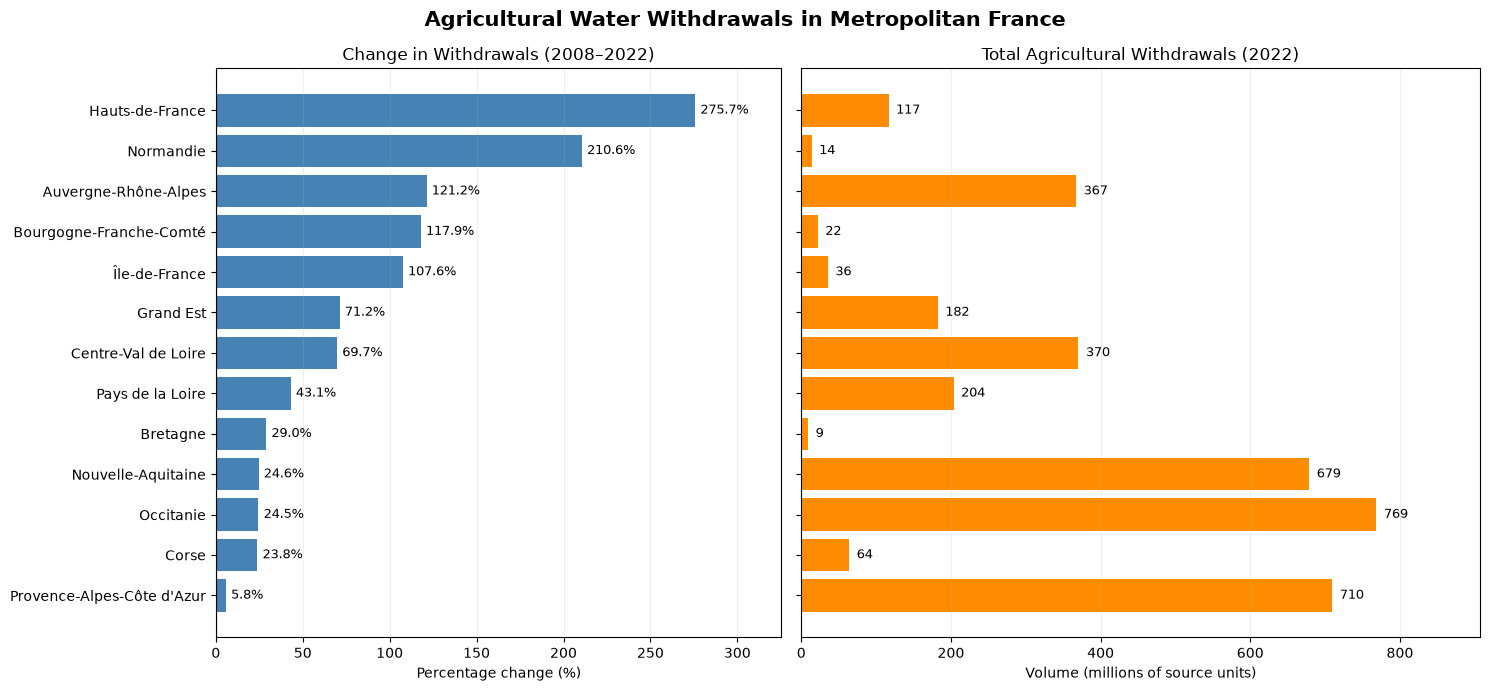

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Sort regions by percentage change
plot_data = comparison_metro.sort_values("change_pct")

# Convert 2022 withdrawals to millions of source units
plot_data["volume_2022_million"] = plot_data[2022] / 1e6

# Create two aligned charts
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(15, 7),
    sharey=True,
    gridspec_kw={"width_ratios": [1, 1.2]}
)

# Chart 1: Percentage change
ax1.barh(
    plot_data.index,
    plot_data["change_pct"],
    color="steelblue"
)

ax1.set_title("Change in Withdrawals (2008–2022)")
ax1.set_xlabel("Percentage change (%)")
ax1.axvline(0, color="black", linewidth=0.8)
ax1.grid(axis="x", alpha=0.2)

# Chart 2: Absolute withdrawals in 2022
ax2.barh(
    plot_data.index,
    plot_data["volume_2022_million"],
    color="darkorange"
)

ax2.set_title("Total Agricultural Withdrawals (2022)")
ax2.set_xlabel("Volume (millions of source units)")
ax2.grid(axis="x", alpha=0.2)

# Add numerical labels
for i, value in enumerate(plot_data["change_pct"]):
    ax1.text(value + 3, i, f"{value:.1f}%",
             va="center", fontsize=9)

for i, value in enumerate(plot_data["volume_2022_million"]):
    ax2.text(value + 10, i, f"{value:.0f}",
             va="center", fontsize=9)

# Make room for labels
ax1.set_xlim(right=plot_data["change_pct"].max() * 1.18)
ax2.set_xlim(right=plot_data["volume_2022_million"].max() * 1.18)

fig.suptitle(
    "Agricultural Water Withdrawals in Metropolitan France",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 2.6 Agricultural Production — Agreste

This section extracts total agricultural production for the
13 metropolitan French regions between 2010 and 2022.

The dataset provides production values and annual volume indices,
allowing us to distinguish real production changes from price effects.

In [18]:
# Filter total agricultural production for current regions
df_production = df_agreste[
    (df_agreste["TYPE_GEO"] == "REG_ACTUELLE")
    & (df_agreste["LIBELLE"].astype(str).str.startswith("58 -"))
    & (df_agreste["ANNEE"].between(2010, 2022))
].copy()

# Inspect the available regions
display(
    df_production[
        ["GEO", "LIBELLE GEOGRAPHIQUE"]
    ].drop_duplicates()
)

,GEO,LIBELLE GEOGRAPHIQUE
240,R01,Guadeloupe
301,R02,Martinique
362,R03,Guyane
423,R04,La Réunion
484,R06,Mayotte
545,R11,Île-de-France
606,R24,Centre-Val de Loire
667,R27,Bourgogne-Franche-Comté
728,R28,Normandie
789,R32,Hauts-de-France


In [21]:
print("Number of observations:", len(df_production))
print("Number of regions:", df_production["GEO"].nunique())
print("Number of years:", df_production["ANNEE"].nunique())

print("\nMissing values:")
print(df_production.isna().sum())

print("\nObservations by region:")
display(df_production.groupby("GEO")["ANNEE"].nunique())

Number of observations: 169
Number of regions: 13
Number of years: 13

Missing values:
ANNEE                           0
TYPE_GEO                        0
GEO                             0
LIBELLE GEOGRAPHIQUE            0
LIBELLE                         0
Valeur année N-1               13
Indice de volume               13
Valeur année N aux prix N-1    13
Indice de prix                 13
Valeur année N                  0
Indice de valeur               13
dtype: int64

Observations by region:


GEO
R11    13
R24    13
R27    13
R28    13
R32    13
R44    13
R52    13
R53    13
R75    13
R76    13
R84    13
R93    13
R94    13
Name: ANNEE, dtype: int64

In [22]:
# Keep metropolitan regions using the existing GeoDataFrame
metro_codes = "R" + regions["code"].astype(str).str.zfill(2)

df_production = df_production[
    df_production["GEO"].isin(metro_codes)
].copy()

# Check coverage and missing values
print("Observations:", len(df_production))
print("Regions:", df_production["GEO"].nunique())
print("Years:", df_production["ANNEE"].nunique())

display(
    df_production[
        ["ANNEE", "GEO", "Valeur année N", "Indice de volume"]
    ].isna().sum()
)

display(df_production.head())

Observations: 169
Regions: 13
Years: 13


ANNEE                0
GEO                  0
Valeur année N       0
Indice de volume    13
dtype: int64

,ANNEE,TYPE_GEO,GEO,LIBELLE GEOGRAPHIQUE,LIBELLE,Valeur année N-1,Indice de volume,Valeur année N aux prix N-1,Indice de prix,Valeur année N,Indice de valeur
545,2010,REG_ACTUELLE,R11,Île-de-France,"58 - TOTAL PRODUCTION hors subventions, hors j...",NaN,NaN,NaN,NaN,1171.70,NaN
606,2010,REG_ACTUELLE,R24,Centre-Val de Loire,"58 - TOTAL PRODUCTION hors subventions, hors j...",NaN,NaN,NaN,NaN,4076.90,NaN
667,2010,REG_ACTUELLE,R27,Bourgogne-Franche-Comté,"58 - TOTAL PRODUCTION hors subventions, hors j...",NaN,NaN,NaN,NaN,4237.61,NaN
728,2010,REG_ACTUELLE,R28,Normandie,"58 - TOTAL PRODUCTION hors subventions, hors j...",NaN,NaN,NaN,NaN,4726.74,NaN
789,2010,REG_ACTUELLE,R32,Hauts-de-France,"58 - TOTAL PRODUCTION hors subventions, hors j...",NaN,NaN,NaN,NaN,5633.94,NaN


### Methodology — Measuring Agricultural Production Growth

To evaluate whether agricultural production has become decoupled from water withdrawals, we must distinguish **nominal production value** from **real production growth**.

The Agreste dataset provides annual agricultural production values (million EUR) and year-on-year volume indices. We select **total production excluding subsidies and family gardens (category 58)**, which still includes commercial family farming.

Our calculations follow two steps:

**1. Real Production Index (2010 = 100)**

We chain the annual volume indices to measure changes in agricultural production independently of price fluctuations:

$$
I_t = I_{t-1} \times \frac{\text{Volume Index}_t}{100}
$$

**2. Agricultural Production at Constant 2010 Prices**

We apply the resulting index to each region's production value in 2010:

$$
V_t^{real} = V_{2010} \times \frac{I_t}{100}
$$

This produces a comparable measure of agricultural production over time, expressed in million EUR at 2010 reference prices.

**Next step:** By combining these indicators with agricultural water withdrawals (BNPE), we can assess:

- **Decoupling:** whether real agricultural production grows faster than water withdrawals, or grows while withdrawals decrease.
- **Economic water productivity (EUR/m³):** real agricultural production value divided by agricultural water withdrawals.

*Limitation:* Economic water productivity is an aggregate indicator, not a direct measure of irrigation efficiency, since total agricultural production also includes rainfed agriculture.

In [23]:
# Sort observations by region and year
df_production = df_production.sort_values(
    ["GEO", "ANNEE"]
).copy()

# Convert annual volume indices into growth factors
volume_growth = df_production["Indice de volume"].div(100).fillna(1)

# Chain annual growth rates, with 2010 = 100
df_production["production_index"] = (
    volume_growth.groupby(df_production["GEO"]).cumprod() * 100
)

# Inspect the resulting series
display(
    df_production[
        [
            "ANNEE",
            "LIBELLE GEOGRAPHIQUE",
            "Indice de volume",
            "production_index"
        ]
    ].head(13)
)

,ANNEE,LIBELLE GEOGRAPHIQUE,Indice de volume,production_index
545,2010,Île-de-France,NaN,100.000000
3473,2011,Île-de-France,99.3,99.300000
6401,2012,Île-de-France,103.7,102.974100
9329,2013,Île-de-France,99.6,102.562204
12257,2014,Île-de-France,106.3,109.023622
15185,2015,Île-de-France,98.3,107.170221
18113,2016,Île-de-France,73.2,78.448602
21041,2017,Île-de-France,133.1,104.415089
23969,2018,Île-de-France,91.7,95.748636
26897,2019,Île-de-France,108.8,104.174516


In [24]:
display(
    df_production.loc[
        df_production["Indice de volume"].isna(),
        ["ANNEE", "GEO", "LIBELLE GEOGRAPHIQUE"]
    ]
)

,ANNEE,GEO,LIBELLE GEOGRAPHIQUE
545,2010,R11,Île-de-France
606,2010,R24,Centre-Val de Loire
667,2010,R27,Bourgogne-Franche-Comté
728,2010,R28,Normandie
789,2010,R32,Hauts-de-France
850,2010,R44,Grand Est
911,2010,R52,Pays de la Loire
972,2010,R53,Bretagne
1033,2010,R75,Nouvelle-Aquitaine
1094,2010,R76,Occitanie


In [25]:
# Retrieve each region's nominal production value in 2010
base_production = (
    df_production[df_production["ANNEE"] == 2010]
    .set_index("GEO")["Valeur année N"]
)

# Calculate production at constant 2010 prices (million EUR)
df_production["production_real_mEUR"] = (
    df_production["GEO"].map(base_production)
    * df_production["production_index"] / 100
)

# Inspect the results for Île-de-France
display(
    df_production.loc[
        df_production["GEO"] == "R11",
        [
            "ANNEE",
            "Valeur année N",
            "production_index",
            "production_real_mEUR"
        ]
    ]
)

,ANNEE,Valeur année N,production_index,production_real_mEUR
545,2010,1171.70,100.000000,1171.700000
3473,2011,1270.16,99.300000,1163.498100
6401,2012,1464.87,102.974100,1206.547530
9329,2013,1253.65,102.562204,1201.721340
12257,2014,1218.44,109.023622,1277.429784
15185,2015,1163.28,107.170221,1255.713478
18113,2016,844.38,78.448602,919.182266
21041,2017,1094.88,104.415089,1223.431596
23969,2018,1121.13,95.748636,1121.886773
26897,2019,1097.43,104.174516,1220.612809


## 3. Data Preparation and Integration

This section harmonizes regional identifiers and combines agricultural
production data (Agreste) with agricultural water withdrawals (BNPE)
for the 13 metropolitan French regions from 2010 to 2022.

In [26]:
# Compare regional identifiers between Agreste and BNPE

print("BNPE regions:")
display(
    water_region[
        ["geocode_region", "libelle_region"]
    ].drop_duplicates().sort_values("geocode_region")
)

print("Agreste regions:")
display(
    df_production[
        ["GEO", "LIBELLE GEOGRAPHIQUE"]
    ].drop_duplicates().sort_values("GEO")
)

BNPE regions:


,geocode_region,libelle_region
13,1,Guadeloupe
14,2,Martinique
15,3,Guyane
16,4,La Réunion
17,6,Mayotte
0,11,Île-de-France
1,24,Centre-Val de Loire
2,27,Bourgogne-Franche-Comté
3,28,Normandie
4,32,Hauts-de-France


Agreste regions:


,GEO,LIBELLE GEOGRAPHIQUE
545,R11,Île-de-France
606,R24,Centre-Val de Loire
667,R27,Bourgogne-Franche-Comté
728,R28,Normandie
789,R32,Hauts-de-France
850,R44,Grand Est
911,R52,Pays de la Loire
972,R53,Bretagne
1033,R75,Nouvelle-Aquitaine
1094,R76,Occitanie


In [32]:
# Prepare Agreste data for merging
production_merge = df_production[
    [
        "ANNEE",
        "GEO",
        "LIBELLE GEOGRAPHIQUE",
        "production_index",
        "production_real_mEUR"
    ]
].copy()

# Standardize regional codes
production_merge["region_code"] = (
    production_merge["GEO"].str.replace("R", "", regex=False).astype(int)
)

# Merge agricultural production with the complete water panel
df_merged = production_merge.merge(
    water_panel[["year", "geocode_region", "valeur"]],
    left_on=["ANNEE", "region_code"],
    right_on=["year", "geocode_region"],
    how="left",
    validate="one_to_one"
)

# Validate the integration
print("Observations:", len(df_merged))
print("Missing water values:", df_merged["valeur"].isna().sum())

display(df_merged.head())

Observations: 169
Missing water values: 0


,ANNEE,GEO,LIBELLE GEOGRAPHIQUE,production_index,production_real_mEUR,region_code,year,geocode_region,valeur
0,2010,R11,Île-de-France,100.000000,1171.700000,11,2010,11,21969148.01
1,2011,R11,Île-de-France,99.300000,1163.498100,11,2011,11,25605427.00
2,2012,R11,Île-de-France,102.974100,1206.547530,11,2012,11,12523566.00
3,2013,R11,Île-de-France,102.562204,1201.721340,11,2013,11,15658914.00
4,2014,R11,Île-de-France,109.023622,1277.429784,11,2014,11,13575332.00


In [33]:
# Inspect the merge keys in both datasets
print("Agreste:")
print(production_merge[["ANNEE", "region_code"]].dtypes)
display(production_merge[["ANNEE", "region_code"]].head())

print("\nBNPE:")
print(water_region[["year", "geocode_region"]].dtypes)
display(water_region[["year", "geocode_region"]].head())

print("\nBNPE available years:")
print(sorted(water_region["year"].unique()))


Agreste:
ANNEE          int64
region_code    int64
dtype: object


,ANNEE,region_code
545,2010,11
3473,2011,11
6401,2012,11
9329,2013,11
12257,2014,11



BNPE:
year              int32
geocode_region    int64
dtype: object


,year,geocode_region
0,2008,11
1,2008,24
2,2008,27
3,2008,28
4,2008,32



BNPE available years:
[np.int32(2008), np.int32(2022)]


I have to correct the filter that was previously defined

In [34]:
# Build the complete agricultural water withdrawal panel
water_panel = (
    df_bnpe[df_bnpe["usage"] == "agriculture"]
    .groupby(
        ["year", "geocode_region", "libelle_region"],
        as_index=False
    )["valeur"]
    .sum()
)

# Check temporal coverage
print("Available years:", sorted(water_panel["year"].unique()))
print("Number of observations:", len(water_panel))

display(
    water_panel.groupby("year")["geocode_region"].nunique()
)

Available years: [np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022)]
Number of observations: 250


year
2008    13
2009    13
2010    13
2011    13
2012    18
2013    18
2014    18
2015    18
2016    18
2017    18
2018    18
2019    18
2020    18
2021    18
2022    18
Name: geocode_region, dtype: int64

In [35]:
# Inspect agricultural water withdrawal values
display(
    df_merged.groupby("ANNEE")["valeur"]
    .agg(["min", "median", "max", "sum"])
    .round(2)
)

,min,median,max,sum
ANNEE,,,,
2010,6937118.06,102824156.0,705512003.0,3.033125e+09
2011,8525879.96,95929592.0,659550700.0,3.035707e+09
2012,3543903.00,95967112.0,707847665.0,2.901021e+09
2013,5173387.00,125232814.0,644842007.0,2.776331e+09
2014,2991654.00,96828006.0,591750757.0,2.113809e+09
2015,6403779.00,161578847.0,673557315.0,3.217102e+09
2016,9170740.00,117448824.0,719222924.0,3.116279e+09
2017,7237772.00,125538696.0,677609638.0,2.888818e+09
2018,8291804.00,162596834.0,620309261.0,2.968285e+09


## 4. Economic Water Productivity

Economic water productivity is calculated as real agricultural
production value divided by agricultural water withdrawals.

Production is expressed in 2010 reference euros, while water
withdrawals are measured in cubic meters (m³).

The resulting indicator (EUR/m³) measures aggregate economic
production per unit of water withdrawn, rather than technical
irrigation efficiency.

In [36]:
# Calculate economic water productivity (constant 2010 EUR/m³)
df_merged["water_productivity"] = (
    df_merged["production_real_mEUR"] * 1_000_000
    / df_merged["valeur"]
)

# Inspect Île-de-France as an example
display(
    df_merged.loc[
        df_merged["region_code"] == 11,
        [
            "ANNEE",
            "production_real_mEUR",
            "valeur",
            "water_productivity"
        ]
    ].round(2)
)

,ANNEE,production_real_mEUR,valeur,water_productivity
0,2010,1171.70,21969148.01,53.33
1,2011,1163.50,25605427.00,45.44
2,2012,1206.55,12523566.00,96.34
3,2013,1201.72,15658914.00,76.74
4,2014,1277.43,13575332.00,94.10
5,2015,1255.71,30146085.00,41.65
6,2016,919.18,18831644.00,48.81
7,2017,1223.43,20967510.00,58.35
8,2018,1121.89,29162244.00,38.47
9,2019,1220.61,28981474.00,42.12


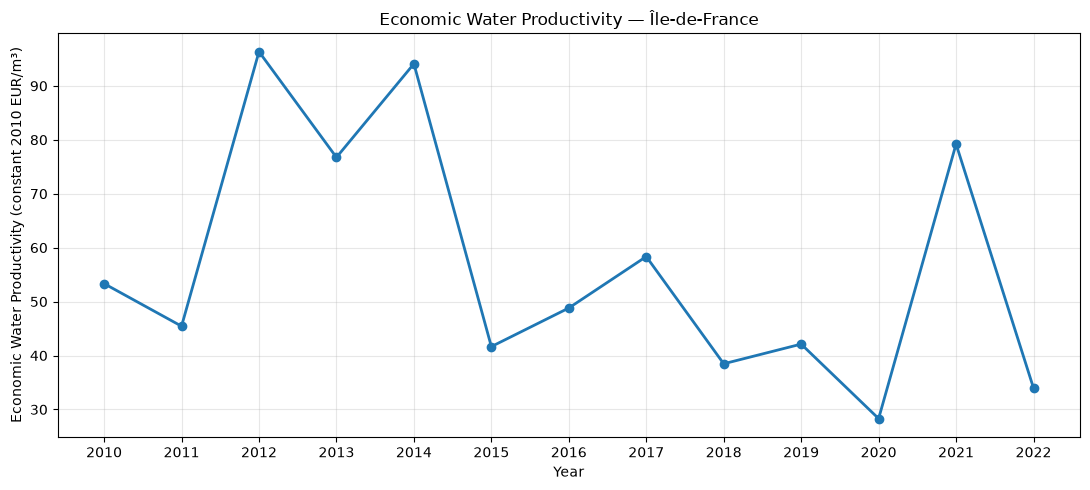

In [37]:
# Plot economic water productivity for Île-de-France
idf = df_merged[df_merged["region_code"] == 11]

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    idf["ANNEE"],
    idf["water_productivity"],
    marker="o",
    linewidth=2
)

ax.set_title("Economic Water Productivity — Île-de-France")
ax.set_xlabel("Year")
ax.set_ylabel("Economic Water Productivity (constant 2010 EUR/m³)")
ax.set_xticks(idf["ANNEE"])
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

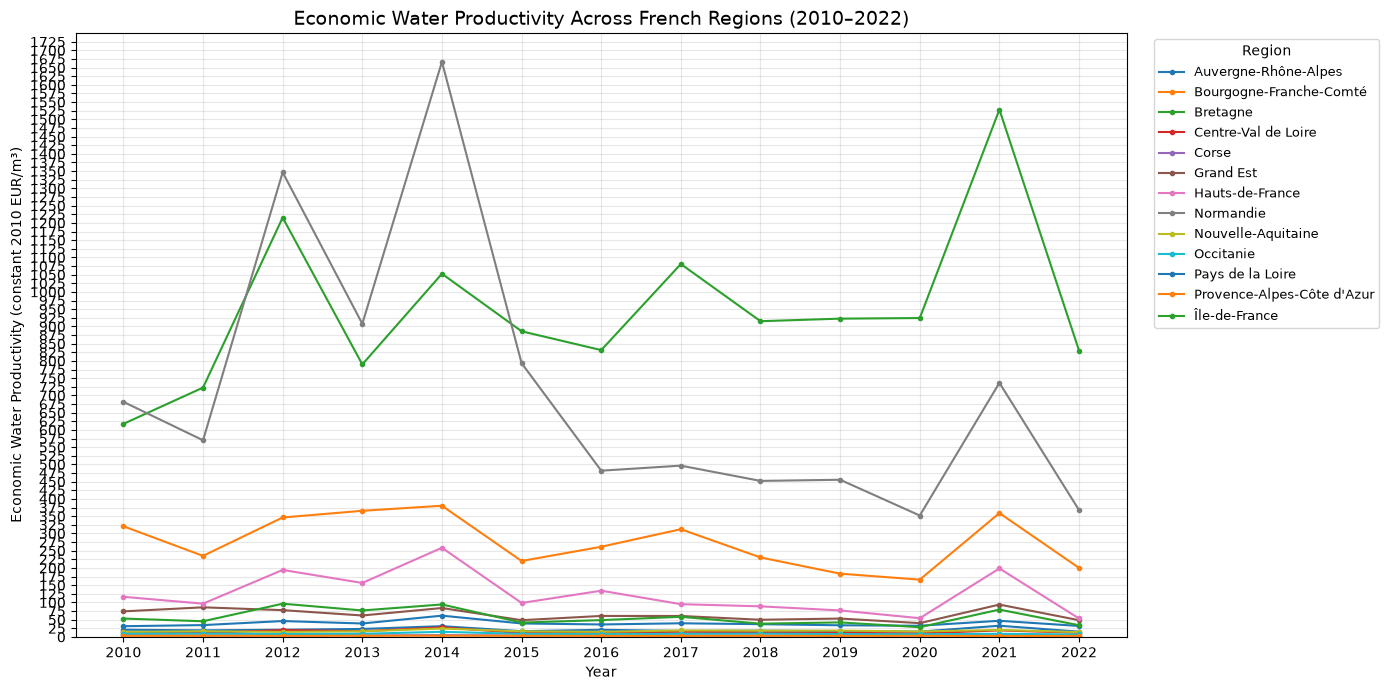

In [38]:
# Economic water productivity across all metropolitan regions
fig, ax = plt.subplots(figsize=(14, 7))

for region, data in df_merged.groupby("LIBELLE GEOGRAPHIQUE"):
    data = data.sort_values("ANNEE")

    ax.plot(
        data["ANNEE"],
        data["water_productivity"],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=region
    )

# Axis labels and numeric scales
ax.set_title(
    "Economic Water Productivity Across French Regions (2010–2022)",
    fontsize=14
)
ax.set_xlabel("Year")
ax.set_ylabel("Economic Water Productivity (constant 2010 EUR/m³)")

ax.set_xticks(range(2010, 2023))
ax.set_ylim(bottom=0)
ax.yaxis.set_major_locator(plt.MultipleLocator(25))

# Improve readability
ax.grid(True, alpha=0.3)
ax.legend(
    title="Region",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

plt.tight_layout()
plt.show()

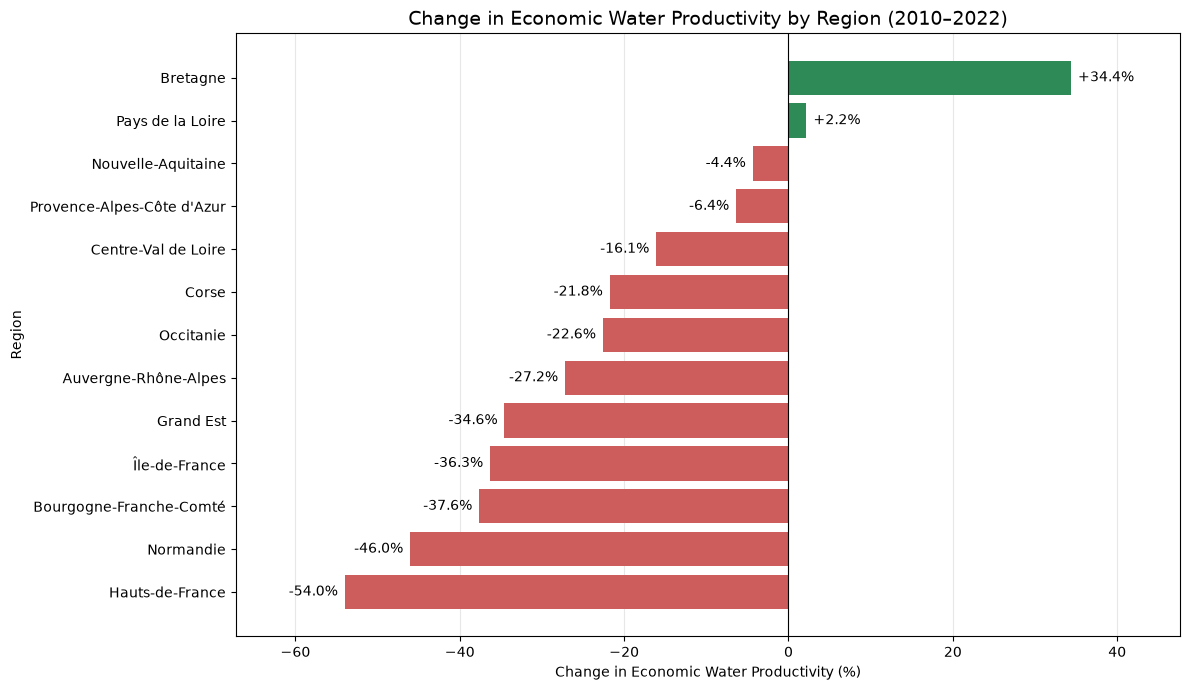

In [39]:
# Compare water productivity between 2010 and 2022
productivity_change = df_merged.pivot(
    index="LIBELLE GEOGRAPHIQUE",
    columns="ANNEE",
    values="water_productivity"
)

# Calculate percentage change
productivity_change["change_pct"] = (
    (productivity_change[2022] / productivity_change[2010] - 1) * 100
)

# Sort regions by percentage change
productivity_change = productivity_change.sort_values("change_pct")

# Plot regional changes
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    productivity_change.index,
    productivity_change["change_pct"],
    color=[
        "seagreen" if value >= 0 else "indianred"
        for value in productivity_change["change_pct"]
    ]
)

# Add percentage labels
for bar, value in zip(bars, productivity_change["change_pct"]):
    ax.annotate(
        f"{value:+.1f}%",
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center"
    )

# Axis formatting
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(
    "Change in Economic Water Productivity by Region (2010–2022)",
    fontsize=14
)
ax.set_xlabel("Change in Economic Water Productivity (%)")
ax.set_ylabel("Region")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

# Leave room for percentage labels
ax.margins(x=0.15)

plt.tight_layout()
plt.show()

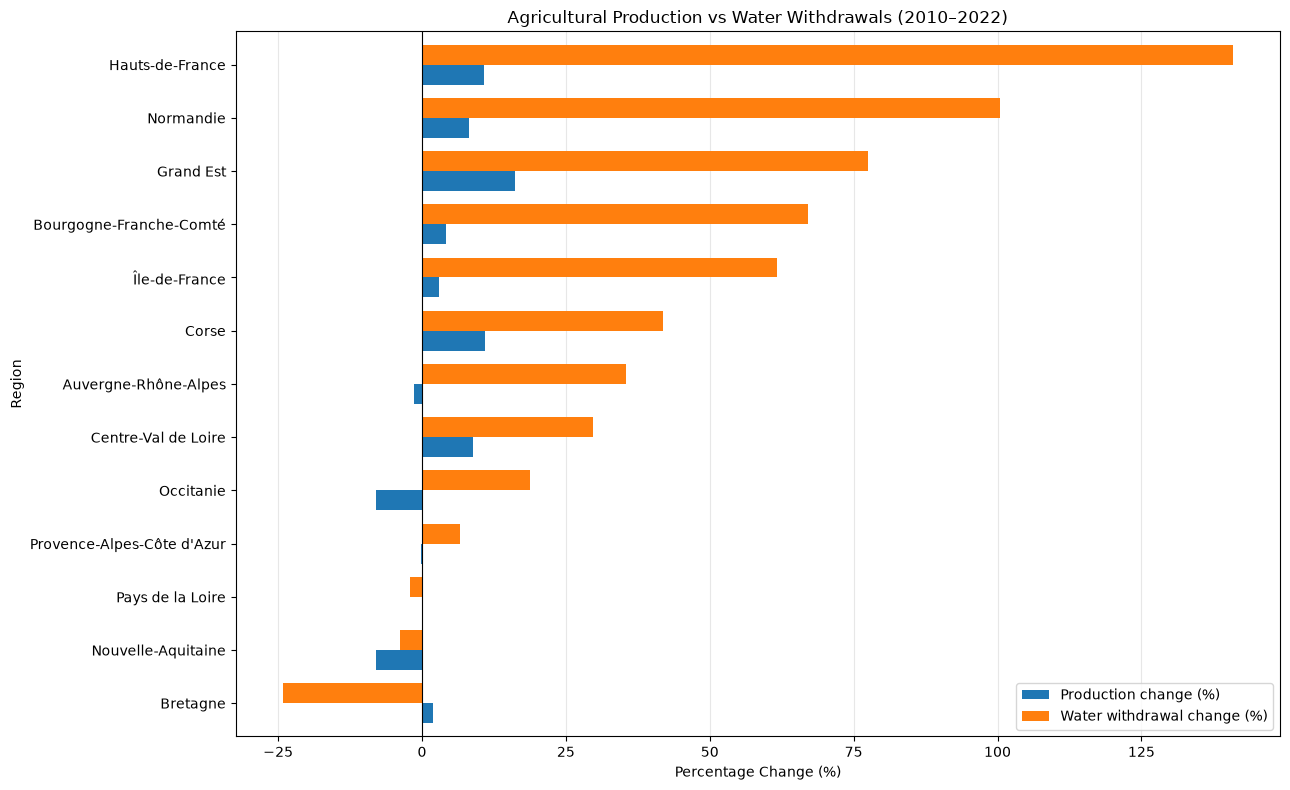

In [40]:
# Compare changes in real production and water withdrawals
comparison_2010_2022 = df_merged.pivot(
    index="LIBELLE GEOGRAPHIQUE",
    columns="ANNEE",
    values=["production_real_mEUR", "valeur"]
)

production_change = (
    comparison_2010_2022["production_real_mEUR"][2022]
    / comparison_2010_2022["production_real_mEUR"][2010] - 1
) * 100

water_change = (
    comparison_2010_2022["valeur"][2022]
    / comparison_2010_2022["valeur"][2010] - 1
) * 100

# Combine both indicators
decoupling_comparison = pd.DataFrame({
    "Production change (%)": production_change,
    "Water withdrawal change (%)": water_change
})

# Sort by water withdrawal change
decoupling_comparison = decoupling_comparison.sort_values(
    "Water withdrawal change (%)"
)

# Plot both indicators
ax = decoupling_comparison.plot(
    kind="barh",
    figsize=(13, 8),
    width=0.75
)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(
    "Agricultural Production vs Water Withdrawals (2010–2022)"
)
ax.set_xlabel("Percentage Change (%)")
ax.set_ylabel("Region")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

## 5. Regional Decoupling Analysis

To assess whether agricultural production and water withdrawals
have become decoupled, both variables are normalized to a common
base year (2010 = 100).

This allows us to compare their relative evolution over time,
regardless of their original measurement units.

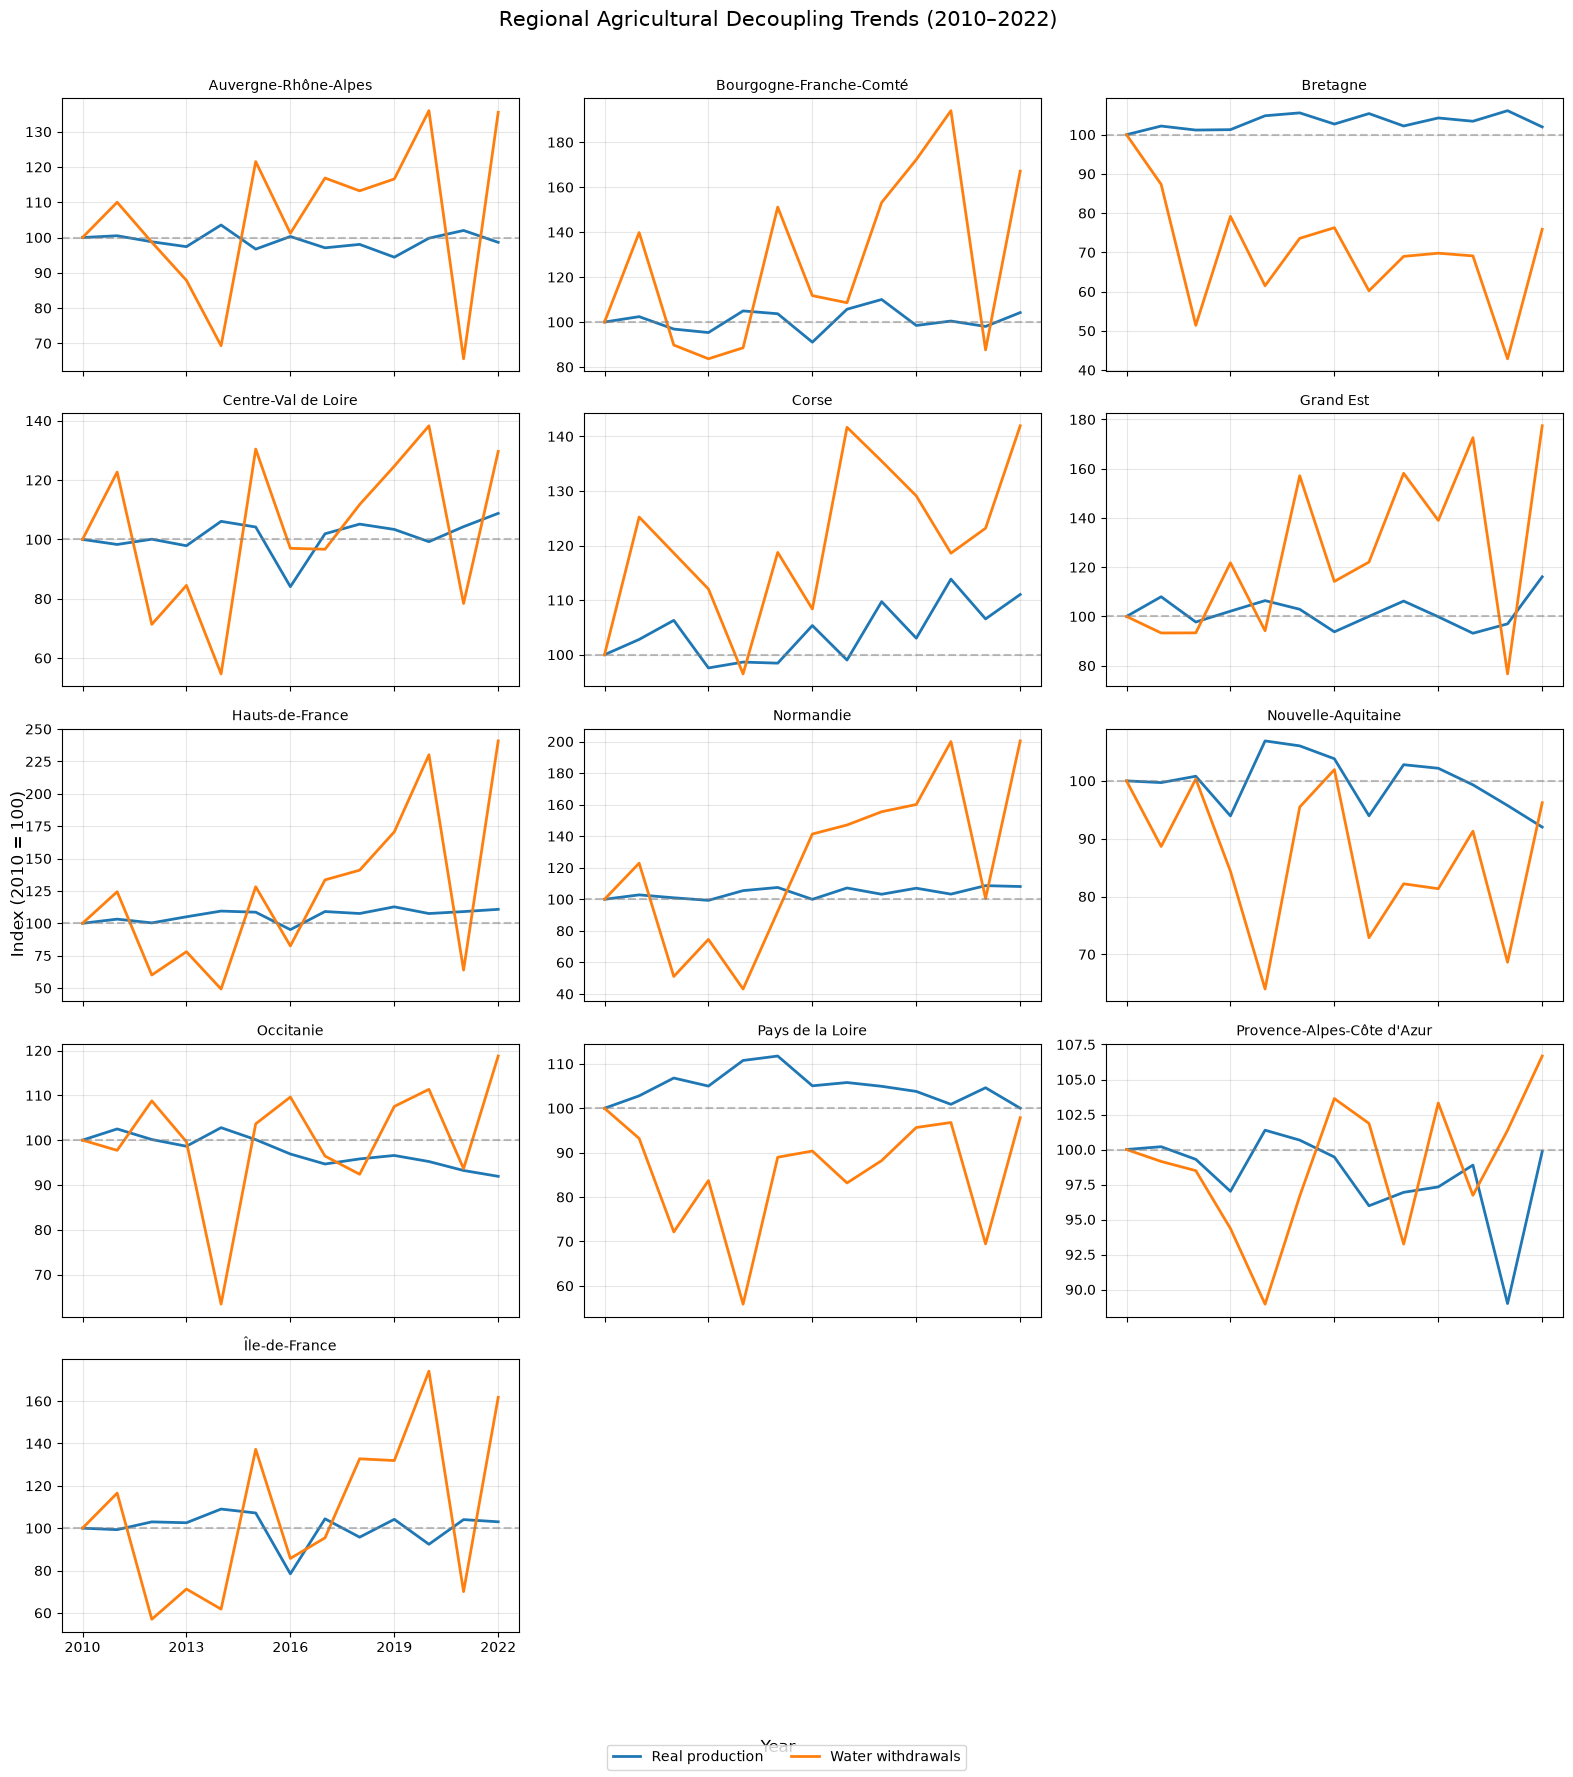

In [41]:
# Normalize water withdrawals to 2010 = 100
df_merged["water_index"] = (
    df_merged["valeur"]
    / df_merged.groupby("region_code")["valeur"].transform("first")
    * 100
)

# Plot production and water withdrawal trends for each region
regions_list = sorted(df_merged["LIBELLE GEOGRAPHIQUE"].unique())

fig, axes = plt.subplots(5, 3, figsize=(16, 18), sharex=True)

for ax, region in zip(axes.flat, regions_list):
    data = df_merged[
        df_merged["LIBELLE GEOGRAPHIQUE"] == region
    ].sort_values("ANNEE")

    ax.plot(
        data["ANNEE"],
        data["production_index"],
        label="Real production",
        linewidth=2
    )

    ax.plot(
        data["ANNEE"],
        data["water_index"],
        label="Water withdrawals",
        linewidth=2
    )

    ax.axhline(100, color="gray", linestyle="--", alpha=0.5)
    ax.set_title(region, fontsize=10)
    ax.grid(alpha=0.3)
    ax.set_xticks([2010, 2013, 2016, 2019, 2022])

# Remove unused panels
for ax in axes.flat[len(regions_list):]:
    ax.set_visible(False)

fig.legend(
    ["Real production", "Water withdrawals"],
    loc="lower center",
    ncol=2
)

fig.suptitle(
    "Regional Agricultural Decoupling Trends (2010–2022)",
    fontsize=15
)

fig.supxlabel("Year")
fig.supylabel("Index (2010 = 100)")

plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.show()

In [42]:
# Compare three-year averages instead of individual years
period_start = (
    df_merged[df_merged["ANNEE"].between(2010, 2012)]
    .groupby("LIBELLE GEOGRAPHIQUE")[
        ["production_real_mEUR", "valeur"]
    ]
    .mean()
)

period_end = (
    df_merged[df_merged["ANNEE"].between(2020, 2022)]
    .groupby("LIBELLE GEOGRAPHIQUE")[
        ["production_real_mEUR", "valeur"]
    ]
    .mean()
)

# Calculate percentage changes between periods
robustness = (
    (period_end / period_start - 1) * 100
).rename(columns={
    "production_real_mEUR": "Production change (%)",
    "valeur": "Water withdrawal change (%)"
})

# Calculate change in economic water productivity
robustness["Water productivity change (%)"] = (
    (
        period_end["production_real_mEUR"] / period_end["valeur"]
    ) / (
        period_start["production_real_mEUR"] / period_start["valeur"]
    ) - 1
) * 100

display(robustness.round(1))

,Production change (%),Water withdrawal change (%),Water productivity change (%)
LIBELLE GEOGRAPHIQUE,,,
Auvergne-Rhône-Alpes,0.4,9.2,-8.1
Bourgogne-Franche-Comté,1.1,36.2,-25.7
Bretagne,2.7,-21.3,30.5
Centre-Val de Loire,4.7,17.8,-11.1
Corse,7.2,11.6,-3.9
Grand Est,0.2,48.9,-32.7
Hauts-de-France,7.9,88.0,-42.6
Normandie,5.4,82.8,-42.4
Nouvelle-Aquitaine,-4.5,-11.4,7.8
